In [ ]:
Problem Statement:Data Preprocessing and Exploratory Data Analysis

Name:Rohan Prakash Wayal
Roll No.:68
Division:A
Batch: T-A3


In [88]:
import pandas as pd

In [89]:
import seaborn as sns

In [90]:
import numpy as np

In [91]:
import matplotlib.pyplot as plt

In [92]:
from sklearn.model_selection import train_test_split

In [93]:
from sklearn.preprocessing import StandardScaler , LabelEncoder

In [87]:
df=pd.read_csv("train (1).csv")

In [47]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [48]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df.drop_duplicates( inplace = True )

In [52]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [53]:
df["Age"].fillna(df["Age"].mean())

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64

In [54]:
df["Embarked"].fillna(df["Embarked"].mode()[0])

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: object

In [55]:
df.drop("Cabin" , axis=1 , inplace=True)

In [56]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [57]:
le =LabelEncoder()

In [58]:
df["Sex"]= le.fit_transform(df["Sex"])

In [59]:
df= pd.get_dummies(df , columns=["Embarked"], drop_first=True)

In [60]:
df.drop(["Name" , "Ticket"], axis=1 , inplace=True)

In [61]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1,0,3,1,22.0,1,0,7.2500,False,True
1,2,1,1,0,38.0,1,0,71.2833,False,False
2,3,1,3,0,26.0,0,0,7.9250,False,True
3,4,1,1,0,35.0,1,0,53.1000,False,True
4,5,0,3,1,35.0,0,0,8.0500,False,True


In [62]:
df.describe()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,0.647587,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,0.477990,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,0.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,1.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,1.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200


In [63]:
df.corr()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
PassengerId,1.000000,-0.005007,-0.035144,0.042939,0.036847,-0.057527,-0.001652,0.012658,-0.033606,0.022148
Survived,-0.005007,1.000000,-0.338481,-0.543351,-0.077221,-0.035322,0.081629,0.257307,0.003650,-0.155660
Pclass,-0.035144,-0.338481,1.000000,0.131900,-0.369226,0.083081,0.018443,-0.549500,0.221009,0.081720
Sex,0.042939,-0.543351,0.131900,1.000000,0.093254,-0.114631,-0.245489,-0.182333,-0.074115,0.125722
Age,0.036847,-0.077221,-0.369226,0.093254,1.000000,-0.308247,-0.189119,0.096067,-0.022405,-0.032523
SibSp,-0.057527,-0.035322,0.083081,-0.114631,-0.308247,1.000000,0.414838,0.159651,-0.026354,0.070941
Parch,-0.001652,0.081629,0.018443,-0.245489,-0.189119,0.414838,1.000000,0.216225,-0.081228,0.063036
Fare,0.012658,0.257307,-0.549500,-0.182333,0.096067,0.159651,0.216225,1.000000,-0.117216,-0.166603
Embarked_Q,-0.033606,0.003650,0.221009,-0.074115,-0.022405,-0.026354,-0.081228,-0.117216,1.000000,-0.496624
Embarked_S,0.022148,-0.155660,0.081720,0.125722,-0.032523,0.070941,0.063036,-0.166603,-0.496624,1.000000


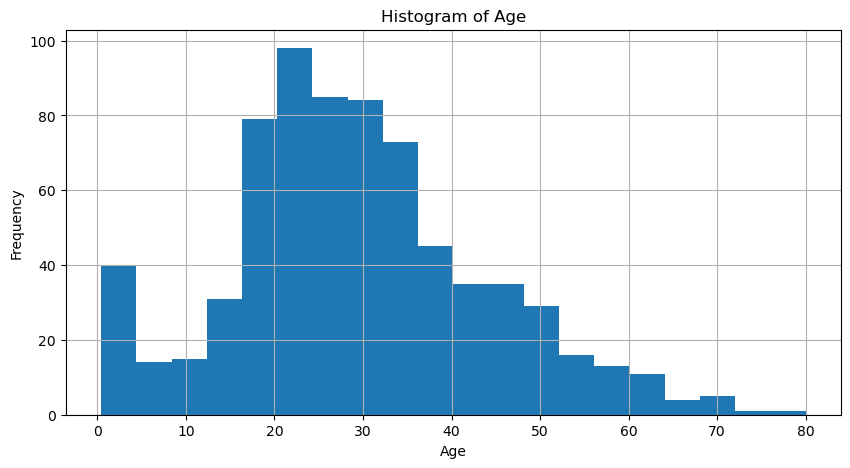

In [65]:
plt.figure(figsize=(10,5))
df["Age"].hist(bins=20)
plt.title("Histogram of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

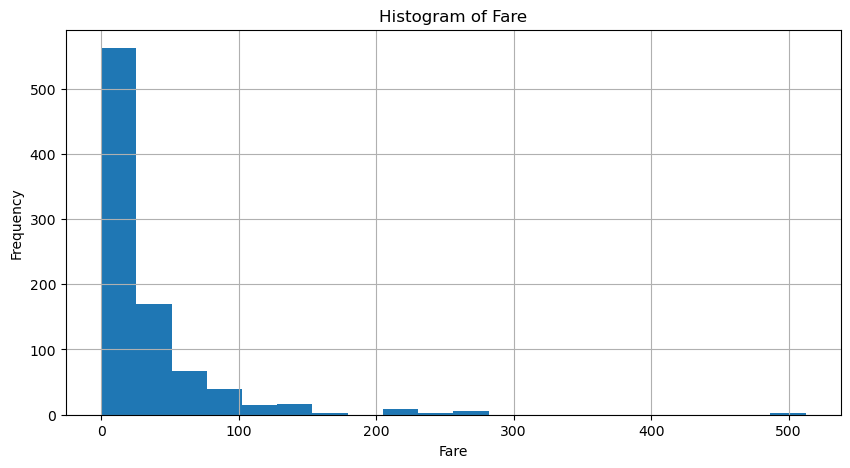

In [67]:
plt.figure(figsize=(10,5))
df["Fare"].hist(bins=20)
plt.title("Histogram of Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

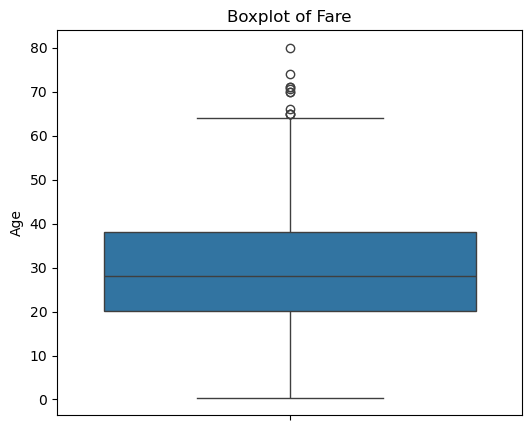

In [68]:
plt.figure(figsize=(6,5))
sns.boxplot(y=df["Age"])
plt.title("Boxplot of Fare")
plt.show()

In [69]:
scaler = StandardScaler()
numerical_columns= ["Age","Fare"]
df[numerical_columns]=scaler.fit_transform(df[numerical_columns])

In [70]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1,0,3,1,-0.530377,1,0,-0.502445,False,True
1,2,1,1,0,0.571831,1,0,0.786845,False,False
2,3,1,3,0,-0.254825,0,0,-0.488854,False,True
3,4,1,1,0,0.365167,1,0,0.420730,False,True
4,5,0,3,1,0.365167,0,0,-0.486337,False,True


In [71]:
X=df.drop("Survived", axis=1)
y=df["Survived"]
X_train , X_test , y_train , y_test =train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


In [72]:
X_train.shape

(712, 9)

In [73]:
X_test.shape

(179, 9)

In [75]:
y_train.shape


(712,)

In [76]:
y_test.shape

(179,)

In [77]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1,0,3,1,-0.530377,1,0,-0.502445,False,True
1,2,1,1,0,0.571831,1,0,0.786845,False,False
2,3,1,3,0,-0.254825,0,0,-0.488854,False,True
3,4,1,1,0,0.365167,1,0,0.420730,False,True
4,5,0,3,1,0.365167,0,0,-0.486337,False,True


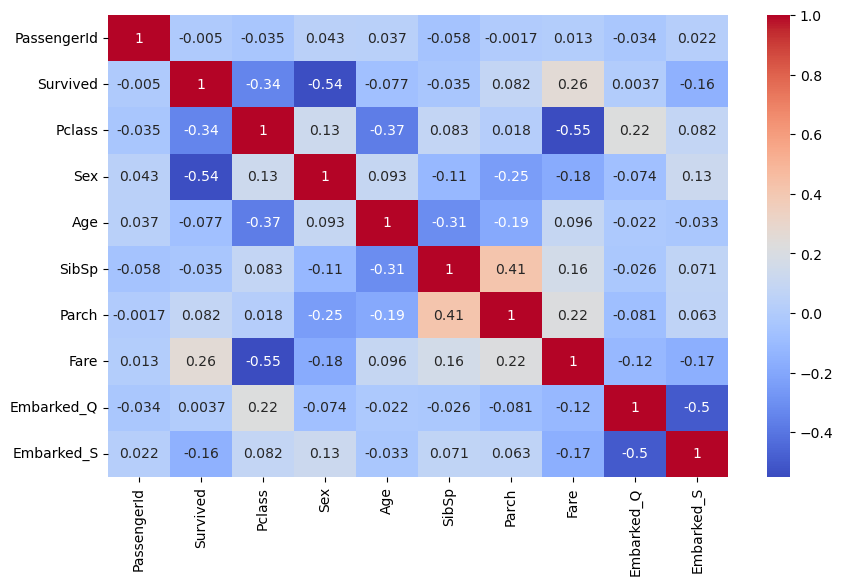

In [81]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

### In this practical we learned about the data preprocessing concept used in machine learning which included checking duplicates of data, removing duplicates, checked if the values are null and to fill the values of integer by mean, median, standard deviation and of objects to mode . We dropped the unnecessary colums such as cabin , Survived as they were making the data complex .We encoded the data  using onehotencoding and label encoding method to encode the data into computer understanding format 